# Phase 3 — Daily Fatigue Table Builder

**Owner:** Member 1 (Data & EDA Lead)  
**Goal:** Reshape the daily stats file into the time-series Member 2 (ML) and Member 3 (frontend) actually need.  
**Time budget:** 45–60 min.  
**Inputs:** `creative_daily_country_os_stats.csv`, `master_creatives.csv` (from Phase 2)  
**Outputs:** `daily_fatigue_table.csv` (creative × date), `daily_fatigue_country_os.csv` (full granularity)

## What this notebook produces

1. **`daily_fatigue_table.csv`** — one row per `creative_id × date`. The main file Member 2 trains fatigue models on and Member 3 uses to draw line charts.
2. **`daily_fatigue_country_os.csv`** — one row per `creative_id × date × country × os`. For deeper slice analysis (e.g., "this creative fatigued in US but not BR").

Both files have these new columns added:
- `days_since_launch` — integer, 1, 2, 3...
- `ctr`, `cvr` — daily click-through and conversion rates
- `ctr_rolling7`, `cvr_rolling7` — 7-day smoothed versions
- `ctr_baseline` — the creative's mean CTR in its first 3 days
- `ctr_decay_pct` — how much current CTR has dropped vs baseline (the fatigue signal)
- `is_alive` — whether the creative was still running on this date (had impressions)

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from datetime import datetime

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 240)

DATA_DIR = Path("")
OUT_DIR  = Path(".")

ID_COLS   = {"advertiser_id", "campaign_id", "creative_id"}
DATE_COLS = {"date", "start_date", "end_date", "creative_launch_date"}

def smart_load(path):
    df = pd.read_csv(path, low_memory=False)
    for c in df.columns:
        if c in ID_COLS:
            df[c] = pd.to_numeric(df[c], errors="coerce").astype("Int64")
        elif c in DATE_COLS:
            df[c] = pd.to_datetime(df[c], errors="coerce")
    return df

raw = smart_load(DATA_DIR / "creative_daily_country_os_stats.csv")
master = pd.read_csv("master_creatives.csv", low_memory=False)
for c in ID_COLS & set(master.columns):
    master[c] = pd.to_numeric(master[c], errors="coerce").astype("Int64")
for c in DATE_COLS & set(master.columns):
    master[c] = pd.to_datetime(master[c], errors="coerce")

print(f"Daily stats:    {len(raw):>10,} rows \u00d7 {raw.shape[1]} cols")
print(f"Master table:   {len(master):>10,} rows \u00d7 {master.shape[1]} cols")
print(f"Distinct creatives in daily: {raw['creative_id'].nunique():,}")
print(f"Distinct creatives in master: {master['creative_id'].nunique():,}")

Daily stats:       192,315 rows × 14 cols
Master table:        1,080 rows × 81 cols
Distinct creatives in daily: 1,080
Distinct creatives in master: 1,080


## 1. Sanity-check the granularity

The daily file should be unique on `(creative_id, date, country, os)`. If there are duplicates here, our aggregation will silently double-count.

In [2]:
key_cols = ["creative_id", "date", "country", "os"]
dups = raw.duplicated(subset=key_cols).sum()
print(f"Duplicate rows on {key_cols}: {dups}")
assert dups == 0, "\u26a0 Duplicates found \u2014 aggregation will double-count"

print(f"\nGranularity is correct \u2713")
print(f"  {raw['creative_id'].nunique():,} creatives \u00d7 {raw['date'].nunique()} dates \u00d7 "
      f"{raw['country'].nunique()} countries \u00d7 {raw['os'].nunique()} OS")

Duplicate rows on ['creative_id', 'date', 'country', 'os']: 0

Granularity is correct ✓
  1,080 creatives × 75 dates × 10 countries × 2 OS


## 2. Country/OS-level table (full granularity)

Add derived columns to the original-granularity file. Save as `daily_fatigue_country_os.csv` for slice analysis later.

In [3]:
def safe_div(num, den):
    den_clean = den.replace(0, np.nan)
    return num / den_clean

country_os = raw.copy()
country_os["ctr"] = safe_div(country_os["clicks"],      country_os["impressions"])
country_os["cvr"] = safe_div(country_os["conversions"], country_os["clicks"])
country_os["viewability_rate"] = safe_div(country_os["viewable_impressions"], country_os["impressions"])
country_os["video_completion_rate"] = safe_div(country_os["video_completions"], country_os["impressions"])

# Save the full-granularity version
country_os = country_os.sort_values(["creative_id", "date", "country", "os"]).reset_index(drop=True)
out_path = OUT_DIR / "daily_fatigue_country_os.csv"
country_os.to_csv(out_path, index=False)
size_mb = out_path.stat().st_size / 1e6
print(f"\u2713 Wrote {out_path}  ({size_mb:.2f} MB, {len(country_os):,} rows \u00d7 {country_os.shape[1]} cols)")

✓ Wrote daily_fatigue_country_os.csv  (26.92 MB, 192,315 rows × 18 cols)


## 3. Aggregate to creative × date (the main fatigue table)

Sum impressions/clicks/conversions/spend/revenue across countries and OS. **Important:** we sum the raw counts *before* computing CTR/CVR — taking a mean of CTRs would weight small slices equally with large ones, which is wrong.

In [4]:
daily = (
    raw.groupby(["creative_id", "campaign_id", "date"], as_index=False)
       .agg(
           impressions          = ("impressions", "sum"),
           viewable_impressions = ("viewable_impressions", "sum"),
           clicks               = ("clicks", "sum"),
           conversions          = ("conversions", "sum"),
           spend_usd            = ("spend_usd", "sum"),
           revenue_usd          = ("revenue_usd", "sum"),
           video_completions    = ("video_completions", "sum"),
           # days_since_launch should be the same across all slices for a given creative-day
           days_since_launch    = ("days_since_launch", "first"),
       )
)

daily["ctr"]  = safe_div(daily["clicks"],      daily["impressions"])
daily["cvr"]  = safe_div(daily["conversions"], daily["clicks"])
daily["cpc"]  = safe_div(daily["spend_usd"],   daily["clicks"])
daily["cpa"]  = safe_div(daily["spend_usd"],   daily["conversions"])
daily["roas"] = safe_div(daily["revenue_usd"], daily["spend_usd"])
daily["viewability_rate"]      = safe_div(daily["viewable_impressions"], daily["impressions"])
daily["video_completion_rate"] = safe_div(daily["video_completions"],     daily["impressions"])
daily["is_alive"] = (daily["impressions"] > 0).astype(int)

print(f"\u2713 Aggregated to creative \u00d7 date: {len(daily):,} rows")
print(f"  Distinct creatives: {daily['creative_id'].nunique():,}")
print(f"  Date span: {daily['date'].min().date()} \u2192 {daily['date'].max().date()}")
print(f"  Avg days per creative: {len(daily) / daily['creative_id'].nunique():.1f}")

✓ Aggregated to creative × date: 52,349 rows
  Distinct creatives: 1,080
  Date span: 2026-01-01 → 2026-03-16
  Avg days per creative: 48.5


## 4. Add rolling averages (the smoothed fatigue signal)

Daily CTR is noisy. A 7-day rolling mean is what you actually want for fatigue charts and ML features.

In [5]:
daily = daily.sort_values(["creative_id", "date"]).reset_index(drop=True)

# 7-day rolling mean per creative (min 3 days so day 3+ has a value, not 7+)
for col, target in [("ctr", "ctr_rolling7"), ("cvr", "cvr_rolling7"),
                    ("impressions", "impressions_rolling7")]:
    daily[target] = (
        daily.groupby("creative_id")[col]
             .transform(lambda s: s.rolling(window=7, min_periods=3).mean())
    )

print("Sample rolling values for one creative:")
sample_id = daily["creative_id"].iloc[0]
print(daily[daily["creative_id"] == sample_id][
    ["date", "days_since_launch", "impressions", "ctr", "ctr_rolling7"]
].head(10).to_string(index=False))

Sample rolling values for one creative:
      date  days_since_launch  impressions      ctr  ctr_rolling7
2026-01-19                  0       940460 0.011299           NaN
2026-01-20                  1       450862 0.009542           NaN
2026-01-21                  2       455904 0.008607      0.009816
2026-01-22                  3       347661 0.008143      0.009398
2026-01-23                  4       380006 0.006513      0.008821
2026-01-24                  5       416192 0.005822      0.008321
2026-01-25                  6       323169 0.004601      0.007790
2026-01-26                  7       314991 0.004581      0.006830
2026-01-27                  8       259893 0.003586      0.005979
2026-01-28                  9       196164 0.003283      0.005218


## 5. Compute baseline and decay

**Baseline** = creative's mean CTR in its first 3 days (when it was "fresh").  
**Decay %** = how much rolling-7 CTR has dropped from baseline.

These two numbers are the heart of fatigue detection. Member 2's ML model will use them as features; the frontend will draw the baseline as a horizontal line and shade the area between it and the rolling CTR red when negative.

In [6]:
# Baseline = mean CTR/CVR in days 0-2 (the first 3 days)
first_3d = daily[daily["days_since_launch"] <= 2]
baseline = (
    first_3d.groupby("creative_id")
            .agg(ctr_baseline=("ctr", "mean"),
                 cvr_baseline=("cvr", "mean"))
            .reset_index()
)

daily = daily.merge(baseline, on="creative_id", how="left")

# Decay: how much the rolling-7 CTR has dropped from baseline (negative = fatiguing)
daily["ctr_decay_pct"] = (
    safe_div(daily["ctr_rolling7"] - daily["ctr_baseline"], daily["ctr_baseline"]) * 100
).round(2)
daily["cvr_decay_pct"] = (
    safe_div(daily["cvr_rolling7"] - daily["cvr_baseline"], daily["cvr_baseline"]) * 100
).round(2)

print("Baseline summary:")
print(daily.groupby("creative_id")["ctr_baseline"].first().describe().round(4))

print("\nDecay summary (last day per creative):")
last_day = daily.sort_values("date").groupby("creative_id").tail(1)
print(last_day["ctr_decay_pct"].describe(percentiles=[.1, .25, .5, .75, .9]).round(2))

Baseline summary:
count    1080.0000
mean        0.0106
std         0.0029
min         0.0044
25%         0.0086
50%         0.0104
75%         0.0122
max         0.0196
Name: ctr_baseline, dtype: float64

Decay summary (last day per creative):
count    1080.00
mean      -78.80
std         6.94
min       -90.78
10%       -86.06
25%       -83.84
50%       -80.30
75%       -75.16
90%       -69.50
max       -44.47
Name: ctr_decay_pct, dtype: float64


## 6. Cross-check our fatigue numbers vs `creative_summary.ctr_decay_pct`

Member 1 sanity check: do our recomputed decay numbers agree with the pre-computed ones in `creative_summary`? If they're close, we're consistent. If they diverge wildly, one of us has a bug.

In [7]:
# Get our last-day decay per creative
our_decay = (
    daily.sort_values("date").groupby("creative_id").tail(1)
         [["creative_id", "ctr_decay_pct"]]
         .rename(columns={"ctr_decay_pct": "ctr_decay_pct_ours"})
)

# Compare to the pre-computed one
compare = master[["creative_id", "ctr_decay_pct", "creative_status"]].merge(
    our_decay, on="creative_id", how="left"
)

# The pre-computed one is in [-1, +inf] (e.g., -0.84 = -84%). Ours is in percent (e.g., -84.0).
# So we multiply theirs by 100 for comparison.
compare["ctr_decay_pct_theirs"] = compare["ctr_decay_pct"] * 100
compare["diff"] = (compare["ctr_decay_pct_ours"] - compare["ctr_decay_pct_theirs"]).abs()

print("Agreement between our decay and Smadex's pre-computed decay:\n")
print(compare["diff"].describe(percentiles=[.5, .9, .99]).round(2))

# Any creatives where we *strongly* disagree?
big_diff = compare[compare["diff"] > 30].sort_values("diff", ascending=False)
print(f"\nCreatives where we disagree by more than 30 percentage points: {len(big_diff)}")
if len(big_diff) > 0:
    print(big_diff.head(5).to_string(index=False))
    print("\n\u2139 Note: small disagreements are expected because we use rolling-7 of last day vs "
          "their first-7 vs last-7 windowing. Big disagreements deserve a look.")

Agreement between our decay and Smadex's pre-computed decay:

count    1080.00
mean        1.26
std         1.83
min         0.00
50%         0.69
90%         2.85
99%         9.55
max        16.47
Name: diff, dtype: float64

Creatives where we disagree by more than 30 percentage points: 0


## 7. Add a per-row creative health score

Same idea as the master-table `health_score`, but computed *for this specific date*. Frontend can plot this as a line going from green to red over time — instant visual fatigue signal.

In [8]:
# Health score per row (0 = dead, 1 = perfectly healthy)
# Component 1: how does today's CTR compare to baseline? (clip to [0, 1.5] then normalize)
ctr_ratio = safe_div(daily["ctr_rolling7"], daily["ctr_baseline"]).clip(0, 1.5) / 1.5
# Component 2: is the creative still getting impressions? (alive flag)
alive_component = daily["is_alive"]
# Combine
daily["daily_health_score"] = (0.7 * ctr_ratio.fillna(0.5) + 0.3 * alive_component).round(3)

print("Daily health score distribution:")
print(daily["daily_health_score"].describe(percentiles=[.1, .5, .9]).round(3))

print("\nSample trajectory (one creative, all days):")
sample = daily[daily["creative_id"] == daily["creative_id"].iloc[0]]
print(sample[["date", "days_since_launch", "ctr_rolling7", "ctr_decay_pct",
              "daily_health_score"]].to_string(index=False))

Daily health score distribution:
count    52349.000
mean         0.527
std          0.135
min          0.343
10%          0.382
50%          0.484
90%          0.753
max          0.842
Name: daily_health_score, dtype: float64

Sample trajectory (one creative, all days):
      date  days_since_launch  ctr_rolling7  ctr_decay_pct  daily_health_score
2026-01-19                  0           NaN            NaN               0.650
2026-01-20                  1           NaN            NaN               0.650
2026-01-21                  2      0.009816           0.00               0.767
2026-01-22                  3      0.009398          -4.26               0.747
2026-01-23                  4      0.008821         -10.14               0.719
2026-01-24                  5      0.008321         -15.23               0.696
2026-01-25                  6      0.007790         -20.64               0.670
2026-01-26                  7      0.006830         -30.42               0.625
2026-01-27        

## 8. Order columns and write `daily_fatigue_table.csv`

In [9]:
COL_ORDER = [
    # IDs and time
    "creative_id", "campaign_id", "date", "days_since_launch",
    # Raw counts
    "impressions", "viewable_impressions", "clicks", "conversions",
    "spend_usd", "revenue_usd", "video_completions",
    # Daily rates
    "ctr", "cvr", "cpc", "cpa", "roas",
    "viewability_rate", "video_completion_rate",
    # Smoothed
    "ctr_rolling7", "cvr_rolling7", "impressions_rolling7",
    # Baseline & decay
    "ctr_baseline", "ctr_decay_pct",
    "cvr_baseline", "cvr_decay_pct",
    # Status
    "is_alive", "daily_health_score",
]
present  = [c for c in COL_ORDER if c in daily.columns]
leftover = [c for c in daily.columns if c not in COL_ORDER]
daily = daily[present + leftover]

out_path = OUT_DIR / "daily_fatigue_table.csv"
daily.to_csv(out_path, index=False)
size_mb = out_path.stat().st_size / 1e6
print(f"\u2713 Wrote {out_path}  ({size_mb:.2f} MB, {len(daily):,} rows \u00d7 {daily.shape[1]} cols)")

# Reload smoke test
reloaded = pd.read_csv(out_path)
assert len(reloaded) == len(daily), "Reload row-count mismatch"
print(f"\u2713 Reload smoke-test passed")

✓ Wrote daily_fatigue_table.csv  (16.00 MB, 52,349 rows × 27 cols)
✓ Reload smoke-test passed


## 9. Visual sanity check: plot one fatigued vs one stable creative

This is what Member 3 will eventually render in the dashboard. If these look reasonable, the data is good.

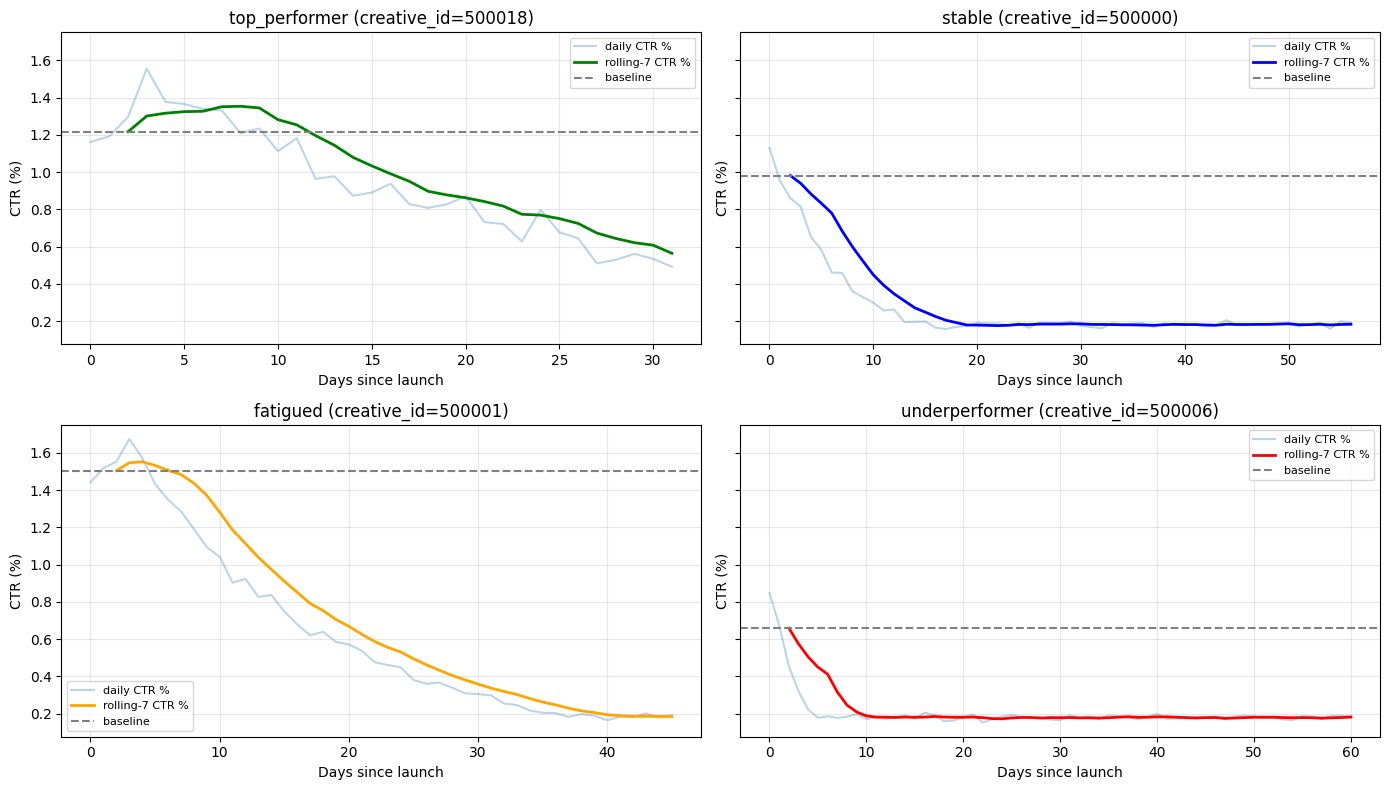

✓ Saved fatigue_examples.png — share this in team chat as a sanity check


In [10]:
import matplotlib.pyplot as plt

# Pick one fatigued and one top_performer creative
fatigued_id = master.loc[master["creative_status"] == "fatigued", "creative_id"].iloc[0]
top_id      = master.loc[master["creative_status"] == "top_performer", "creative_id"].iloc[0]
stable_id   = master.loc[master["creative_status"] == "stable", "creative_id"].iloc[0]
under_id    = master.loc[master["creative_status"] == "underperformer", "creative_id"].iloc[0]

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)

for ax, (cid, label, color) in zip(
    axes.flat,
    [(top_id, "top_performer", "green"),
     (stable_id, "stable", "blue"),
     (fatigued_id, "fatigued", "orange"),
     (under_id, "underperformer", "red")]):
    
    s = daily[daily["creative_id"] == cid].sort_values("days_since_launch")
    ax.plot(s["days_since_launch"], s["ctr"] * 100, alpha=0.3, label="daily CTR %")
    ax.plot(s["days_since_launch"], s["ctr_rolling7"] * 100, color=color, lw=2, label="rolling-7 CTR %")
    if not s["ctr_baseline"].isna().all():
        ax.axhline(s["ctr_baseline"].iloc[0] * 100, ls="--", color="gray", label="baseline")
    ax.set_title(f"{label} (creative_id={cid})")
    ax.set_xlabel("Days since launch")
    ax.set_ylabel("CTR (%)")
    ax.legend(loc="best", fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("fatigue_examples.png", dpi=120, bbox_inches="tight")
plt.show()
print("\u2713 Saved fatigue_examples.png \u2014 share this in team chat as a sanity check")

## 10. Done-when checklist

- [ ] §1: granularity check passed (no duplicates on `creative_id × date × country × os`)
- [ ] §3: aggregated row count looks right (~17k–20k rows = ~17 days × 1,080 creatives)
- [ ] §6: agreement with Smadex's `ctr_decay_pct` is reasonable (most diffs <10pp)
- [ ] §8: `daily_fatigue_table.csv` and `daily_fatigue_country_os.csv` written and reload
- [ ] §9: the four example fatigue charts look right (top_performer flat-or-rising, fatigued declining, etc.)
- [ ] Tell the team in chat: *"daily_fatigue_table.csv ready. Use `ctr_rolling7` for charts, `ctr_decay_pct` and `daily_health_score` as features."*

**Green → Member 1's data work is essentially done. Now switch to mining the 5 insights for Phase 4 while ML/frontend/pitch teams run with your tables.**